In [1]:

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from pathlib import Path
from scipy import sparse

from sklearn.metrics import (
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score,
    f1_score
)

BASE_DIR = Path(
    "/content/drive/MyDrive/Colab Notebooks/data"
)

PROCESSED_DIR = BASE_DIR / "processed"
SELECTION_DIR = BASE_DIR / "feature_selection"

RESULTS_DIR = Path(
    "/content/drive/MyDrive/Colab Notebooks/results"
)

MODEL_DIR = RESULTS_DIR / "models"

feature_groups = ["Radiom", "RadioClin", "RadioClinLab"]
targets = ["ICU", "mechanical_ventilation", "death"]

results_df = pd.read_csv(
    RESULTS_DIR / "model_comparison.csv"
)

Y_test = pd.read_csv(
    PROCESSED_DIR / "Y_test.csv"
)

print("Evaluation data loaded.")
print("Saved experiment results:", results_df.shape)
print("Test labels:", Y_test.shape)


Evaluation data loaded.
Saved experiment results: (45, 11)
Test labels: (720, 3)


In [2]:

def load_matrix(directory, name):
    npy_path = directory / f"{name}.npy"
    npz_path = directory / f"{name}.npz"

    if npy_path.exists():
        return np.load(npy_path)

    if npz_path.exists():
        return sparse.load_npz(npz_path)

    raise FileNotFoundError(
        f"Could not find {npy_path} or {npz_path}"
    )

def safe_model_name(model_name):
    return model_name.lower().replace(" ", "_")

print("Matrix loader ready.")


Matrix loader ready.


In [3]:

group = "RadioClinLab"
target = "ICU"
model_name = "Logistic Regression"

model_path = MODEL_DIR / (
    f"{group}_{target}_{safe_model_name(model_name)}.joblib"
)

if not model_path.exists():
    raise FileNotFoundError(f"Model not found: {model_path}")

model = joblib.load(model_path)

selected_indices = np.load(
    SELECTION_DIR
    / f"{group}_{target}_selected_indices.npy"
).astype(int)

X_test_full = load_matrix(
    PROCESSED_DIR,
    f"{group}_X_test"
)

X_test_selected = X_test_full[:, selected_indices]
y_test = Y_test[target].astype(int).to_numpy()

probabilities = model.predict_proba(X_test_selected)[:, 1]
predictions = model.predict(X_test_selected)

print("Model loaded:", model_name)
print("Test matrix:", X_test_selected.shape)
print("ROC-AUC:", round(roc_auc_score(y_test, probabilities), 4))


Model loaded: Logistic Regression
Test matrix: (720, 148)
ROC-AUC: 0.7214


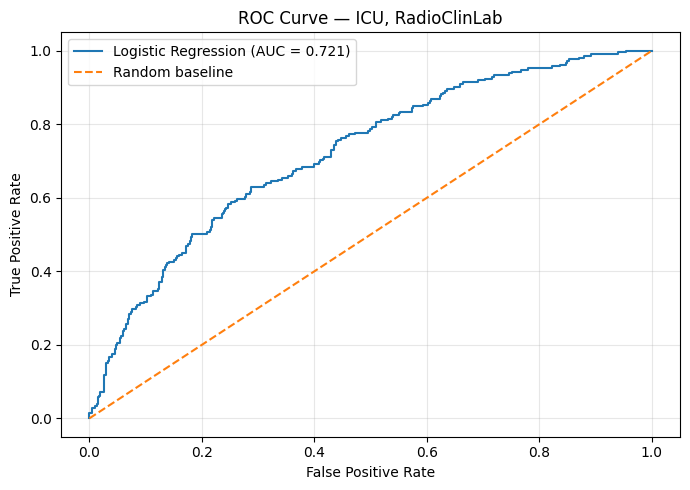

In [4]:

fpr, tpr, thresholds = roc_curve(y_test, probabilities)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"{model_name} (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"ROC Curve — {target}, {group}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


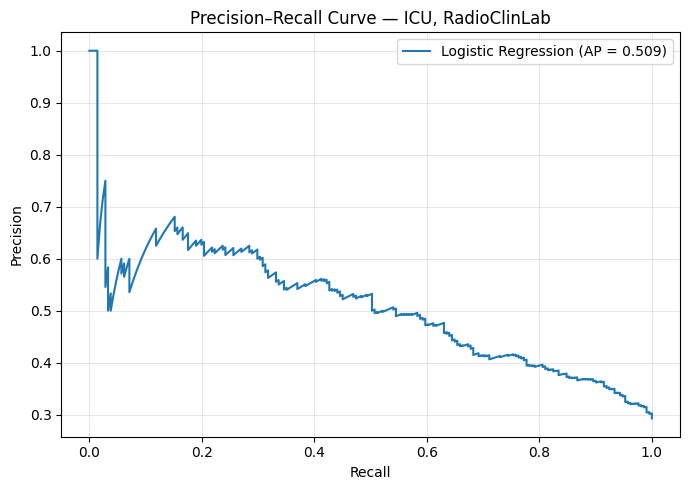

In [5]:

precision, recall, pr_thresholds = precision_recall_curve(
    y_test, probabilities
)

average_precision = average_precision_score(
    y_test, probabilities
)

plt.figure(figsize=(7, 5))
plt.plot(
    recall,
    precision,
    label=f"{model_name} (AP = {average_precision:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision–Recall Curve — {target}, {group}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


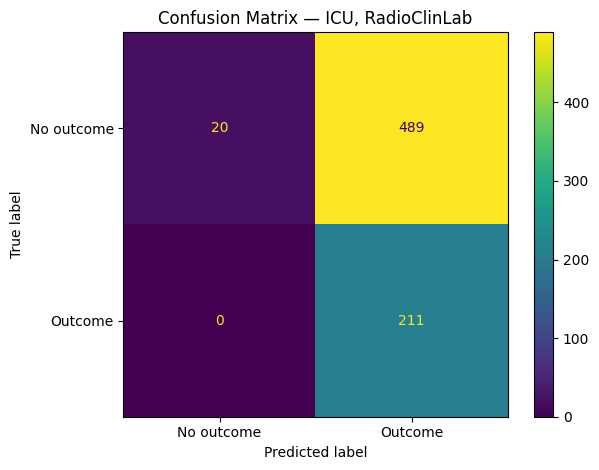

              precision    recall  f1-score   support

  No outcome       1.00      0.04      0.08       509
     Outcome       0.30      1.00      0.46       211

    accuracy                           0.32       720
   macro avg       0.65      0.52      0.27       720
weighted avg       0.80      0.32      0.19       720



In [6]:

cm = confusion_matrix(y_test, predictions, labels=[0, 1])

display_labels = ["No outcome", "Outcome"]

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)

disp.plot()
plt.title(f"Confusion Matrix — {target}, {group}")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    predictions,
    labels=[0, 1],
    target_names=display_labels,
    zero_division=0
))


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


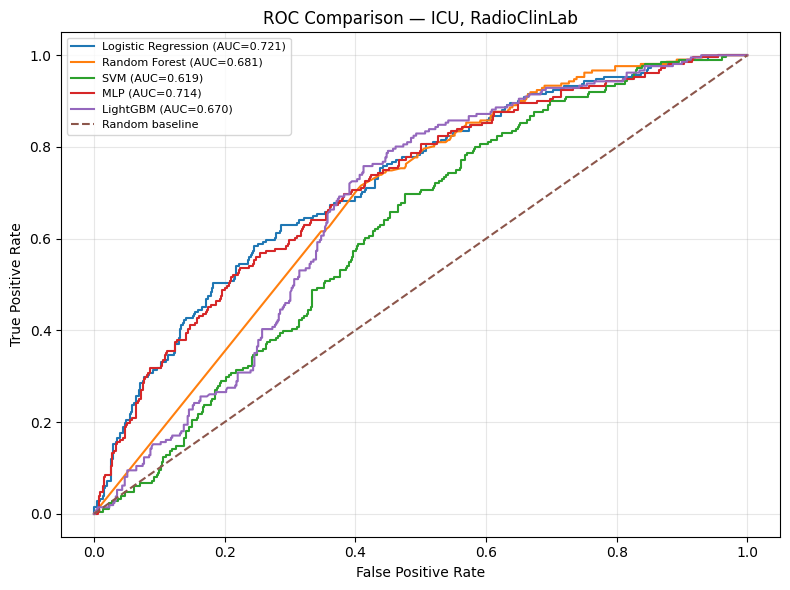

In [7]:

group = "RadioClinLab"
target = "ICU"

selected_indices = np.load(
    SELECTION_DIR
    / f"{group}_{target}_selected_indices.npy"
).astype(int)

X_test_full = load_matrix(
    PROCESSED_DIR,
    f"{group}_X_test"
)

X_test_selected = X_test_full[:, selected_indices]
y_test = Y_test[target].astype(int).to_numpy()

model_names = [
    "Logistic Regression",
    "Random Forest",
    "SVM",
    "MLP",
    "LightGBM"
]

plt.figure(figsize=(8, 6))

for model_name in model_names:
    model_path = MODEL_DIR / (
        f"{group}_{target}_{safe_model_name(model_name)}.joblib"
    )

    model = joblib.load(model_path)
    probabilities = model.predict_proba(X_test_selected)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, probabilities)
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC={roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"ROC Comparison — {target}, {group}")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [8]:

for target in targets:
    print(f"\nPerformance for {target}")

    display(
        results_df[results_df["Target"] == target]
        .sort_values("ROC-AUC", ascending=False)[
            [
                "Feature Group",
                "Model",
                "Accuracy",
                "Precision",
                "Recall",
                "F1 Score",
                "ROC-AUC",
                "PR-AUC (Average Precision)"
            ]
        ]
        .round(3)
    )



Performance for ICU


,Feature Group,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC (Average Precision)
30,RadioClinLab,Logistic Regression,0.321,0.301,1.000,0.463,0.721,0.509
0,Radiom,Logistic Regression,0.306,0.296,0.995,0.457,0.717,0.502
33,RadioClinLab,MLP,0.315,0.300,1.000,0.461,0.714,0.493
15,RadioClin,Logistic Regression,0.308,0.298,1.000,0.459,0.684,0.460
31,RadioClinLab,Random Forest,0.301,0.296,1.000,0.456,0.681,0.409
34,RadioClinLab,LightGBM,0.336,0.306,1.000,0.469,0.670,0.389
4,Radiom,LightGBM,0.306,0.297,1.000,0.458,0.644,0.377
2,Radiom,SVM,0.303,0.296,1.000,0.457,0.632,0.370
16,RadioClin,Random Forest,0.296,0.294,1.000,0.454,0.632,0.365
1,Radiom,Random Forest,0.294,0.293,1.000,0.454,0.631,0.368



Performance for mechanical_ventilation


,Feature Group,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC (Average Precision)
35,RadioClinLab,Logistic Regression,0.343,0.308,0.967,0.467,0.737,0.552
20,RadioClin,Logistic Regression,0.321,0.303,0.986,0.463,0.712,0.538
38,RadioClinLab,MLP,0.315,0.302,0.995,0.464,0.711,0.535
5,Radiom,Logistic Regression,0.315,0.300,0.981,0.460,0.695,0.513
8,Radiom,MLP,0.317,0.303,0.995,0.464,0.695,0.520
23,RadioClin,MLP,0.314,0.301,0.991,0.462,0.691,0.519
21,RadioClin,Random Forest,0.311,0.300,0.991,0.461,0.686,0.423
24,RadioClin,LightGBM,0.333,0.306,0.981,0.467,0.671,0.403
6,Radiom,Random Forest,0.314,0.302,0.995,0.463,0.665,0.407
36,RadioClinLab,Random Forest,0.319,0.303,0.991,0.464,0.665,0.404



Performance for death


,Feature Group,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC (Average Precision)
41,RadioClinLab,Random Forest,0.200,0.172,1.000,0.294,0.730,0.317
40,RadioClinLab,Logistic Regression,0.240,0.179,0.992,0.303,0.722,0.352
43,RadioClinLab,MLP,0.228,0.177,0.992,0.300,0.713,0.354
44,RadioClinLab,LightGBM,0.272,0.184,0.983,0.311,0.713,0.276
25,RadioClin,Logistic Regression,0.224,0.175,0.983,0.297,0.709,0.334
10,Radiom,Logistic Regression,0.240,0.179,0.992,0.303,0.701,0.335
26,RadioClin,Random Forest,0.183,0.169,1.000,0.290,0.694,0.270
28,RadioClin,MLP,0.199,0.170,0.983,0.290,0.694,0.312
11,Radiom,Random Forest,0.194,0.171,1.000,0.293,0.693,0.270
13,Radiom,MLP,0.214,0.173,0.983,0.294,0.690,0.319


In [9]:

best_models = (
    results_df
    .sort_values("ROC-AUC", ascending=False)
    .groupby("Target", as_index=False)
    .first()
)

display(best_models[
    ["Target", "Feature Group", "Model", "ROC-AUC", "F1 Score"]
])

best_models.to_csv(
    RESULTS_DIR / "best_models_by_target.csv",
    index=False
)

print("Saved best-model summary.")


,Target,Feature Group,Model,ROC-AUC,F1 Score
0,ICU,RadioClinLab,Logistic Regression,0.721431,0.463227
1,death,RadioClinLab,Random Forest,0.729500,0.294118
2,mechanical_ventilation,RadioClinLab,Logistic Regression,0.736582,0.466742


Saved best-model summary.
